# Classroom occupancy: how the international classrooms are really used
### International class rooms, Gedung Tokong Nanas (Telkom University), odd semester 2026/2027

Before the renovation the international classes had 34 to 36 classrooms (floors 3 and 9). After it there will be **32**:
20 on floor 3 and 12 on floor 2. The office (ICAO) noticed that many rooms sit unused, some of them for whole days,
while others are always full. Two of the rooms are given up to expand the international student lounge (part of the office's
international branding). Student numbers are still expected to grow, so 32 rooms must also leave room for that.

So the questions are:
1. **How are the rooms used today?** Which rooms are busy, which are idle, and when is the building at its peak?
2. **What if each faculty gets its own rooms?** With class times left exactly as they are, do the classes fit,
   and does a shared reserve of rooms always stay free?
3. **Is 32 classrooms enough** after the renovation?

Overtime classes and timetable errors found along the way are in the appendix.

> **Data:** the real timetable export for the odd semester 2026/2027 (290 weekly classes), used with permission.
> Lecturer codes are replaced with anonymous IDs and the raw export is not published. See `scripts/prepare_data.py`.

In [1]:
import sys, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import occupancy as oc

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 110)

BLUE, ORANGE, RED, GRAY_BAR = "#2a78d6", "#eb6834", "#d03b3b", "#b9c3d3"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
})
IMG = Path.cwd().parent / "images" / "analysis"
IMG.mkdir(parents=True, exist_ok=True)

schedule, rooms = oc.load()
reg = oc.regular(schedule)
NOW = len(rooms)
print(f"classes per week: {len(schedule)} | class groups: {schedule.class_group.nunique()} | "
      f"programs: {schedule.program.nunique()} | rooms used this semester: {NOW} "
      f"(floor 3: {(rooms.floor == 3).sum()}, floor 9: {(rooms.floor == 9).sum()})")
schedule.head()

classes per week: 290 | class groups: 55 | programs: 12 | rooms used this semester: 31 (floor 3: 15, floor 9: 16)


,session_id,course_code,course_name,class_group,program,lecturer_id,day,start_time,end_time,duration_hours,room_id,floor,valid_from,start_min,end_min
0,S001,BBK2DAB3,PENGEMBANGAN APLIKASI WEBSITE,BS1SI-49-REG-01-INT,S1 Sistem Informasi,L106,Mon,06:30,09:30,3.0,KU3.03.06,3,2026-09-14,390,570
1,S002,DEK4JBB3,ENTERPRISE RESOURCE PLANNING,AB-47-INT,S1 Administrasi Bisnis ( International Class ),L096,Mon,07:30,10:30,3.0,KU3.03.05,3,2026-09-14,450,630
2,S003,ABK3CAB3,OTOMATISASI INDUSTRI,BS1TE-48-REG-01-INT,S1 Teknik Elektro,L079,Mon,07:30,10:30,3.0,KU3.03.14,3,2026-09-14,450,630
3,S004,UCK1FDB1,MATERIAL DAN PROSES MANUFAKTUR,BS1TE-50-REG-01-INT,S1 Teknik Elektro,L145,Mon,07:30,08:30,1.0,KU3.03.15,3,2026-09-14,450,510
4,S005,FAK2CAB2,SEMIOTICS AND VISUAL LANGUAGE,BS1DK-49-INT-01,S1 DKV International,L003,Mon,07:30,09:30,2.0,KU3.03.21,3,2026-09-14,450,570


## 1. Checking the timetable

Before measuring anything, check that the timetable makes sense: no room, class group or lecturer in two places at once,
nothing during Friday prayer, nothing at impossible hours. LAC language classes are left out of this check: LAC sets its
own timetable in fixed packages, where parallel groups with the same lecturer are expected.

In [2]:
issues = oc.data_issues(schedule)
issues

,issue,day,sessions,detail
0,class group in two places,Fri,"S248, S252",BS1MB-47-REG-02-INT: BAHASA INDONESIA 06:30-08:30 (KU3.03.19) and E-COMMERCE 07:30-11:30 (KU3.09.05)
1,class during Friday prayer,Fri,S265,STRATEGI DAN KEBIJAKAN BISNIS (AB-49-INT) 09:30-13:30
2,likely input error (late night),Sat,S290,"PRAKTIKUM SINYAL DISKRET, OTOMATISASI, & IOT (BS1TE-48-REG-01-INT) 20:30-23:30"


Three entries need a second look (listed again in the appendix). The Saturday class recorded at 20:30 to 23:30 is most likely
an input error and is left out of the numbers below.

## 2. A first look with SQL

The same data is loaded into SQLite for the basic questions (queries in `sql/queries.sql`).

In [3]:
con = sqlite3.connect(":memory:")
schedule.drop(columns=["start_min", "end_min"]).assign(day=schedule.day.astype(str)).to_sql("schedule", con, index=False)
rooms.to_sql("rooms", con, index=False)

queries = {}
for block in (Path.cwd().parent / "sql" / "queries.sql").read_text().split("-- name: ")[1:]:
    name, body = block.split("\n", 1)
    queries[name.strip()] = body.strip()

def q(name):
    return pd.read_sql(queries[name], con)

q("classes_per_day")

,day,classes,room_hours,class_groups
0,Mon,51,146.0,36
1,Tue,79,191.0,44
2,Wed,62,165.0,37
3,Thu,54,153.0,37
4,Fri,37,91.0,24
5,Sat,7,16.0,6


In [4]:
q("classes_per_program")

,program,classes,room_hours
0,S1 International ICT Business,46,145.0
1,S1 DKV International,30,79.0
2,S1 Akuntansi,28,76.0
3,S1 Ilmu Komunikasi,26,74.0
4,S1 Administrasi Bisnis ( International Class ),26,72.0
5,LAC,36,72.0
6,S1 Sistem Informasi,24,67.0
7,S1 Teknik Elektro,20,50.0
8,S1 Teknik Industri,19,42.0
9,S1 Teknik Telekomunikasi,13,33.0


In [5]:
q("utilization_by_floor")

,floor,rooms,booked_hours,utilization_pct
0,3,15,333.0,40.4
1,9,16,413.0,46.9


Window functions answer the next questions: ranking rooms inside each floor, the busiest slot of each day,
each program's share of overtime, and the free gaps between classes in the same room.

In [6]:
q("room_rank_by_floor")

,floor,room_id,booked_hours,rank_in_floor,vs_floor_avg
0,3,KU3.03.09,34.0,1,11.8
1,3,KU3.03.06,33.0,2,10.8
2,3,KU3.03.21,32.0,3,9.8
3,3,KU3.03.19,31.0,4,8.8
4,3,KU3.03.07,29.0,5,6.8
5,3,KU3.03.05,28.0,6,5.8
6,3,KU3.03.18,28.0,6,5.8
7,3,KU3.03.14,24.0,8,1.8
8,3,KU3.03.04,20.0,9,-2.2
9,3,KU3.03.02,14.0,10,-8.2


In [7]:
q("peak_slot_per_day")

,day,busiest_slot,rooms_in_use
0,Mon,11:00,20
1,Tue,09:30,23
2,Wed,14:30,25
3,Thu,14:30,22
4,Fri,09:30,16
5,Sat,08:30,3


In [8]:
q("overtime_share_by_program")

,program,weekday_classes,overtime_classes,overtime_pct,overtime_total
0,S1 International ICT Business,46,10,21.7,22
1,S1 Akuntansi,28,5,17.9,22
2,S1 Administrasi Bisnis ( International Class ),26,2,7.7,22
3,S1 Sistem Informasi,24,2,8.3,22
4,S1 DKV International,30,1,3.3,22
5,S1 Informatika,9,1,11.1,22
6,S1 Teknik Elektro,19,1,5.3,22


In [9]:
q("gaps_between_classes")

,room_id,day,free_from,free_until,gap_minutes
0,KU3.03.06,Fri,08:30,13:30,300
1,KU3.03.09,Thu,08:30,13:30,300
2,KU3.03.17,Fri,10:00,15:00,300
3,KU3.03.15,Tue,10:00,14:30,270
4,KU3.03.02,Fri,10:00,14:00,240
5,KU3.03.02,Tue,10:00,14:00,240
6,KU3.03.09,Wed,10:30,14:30,240
7,KU3.03.11,Tue,10:00,14:00,240
8,KU3.03.19,Fri,08:30,12:30,240
9,KU3.09.04,Thu,10:30,14:30,240


# Part 1. How the rooms are used today

## 3. Use per room

Utilization = hours a room is booked during operating hours ÷ 55 hours (Monday to Friday, 06:30 to 17:30).

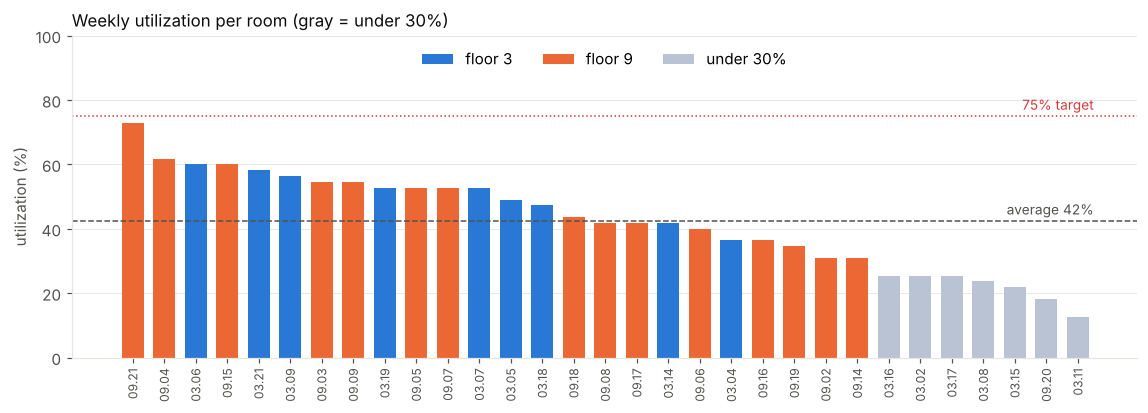

rooms used: 31 | average utilization: 42% | rooms at 75% or more: 0 | rooms under 30%: 7 | busiest KU3.09.21 73% | quietest KU3.03.11 13%
free room-hours per week inside operating hours: 981 of 1705


In [10]:
util = oc.room_utilization(reg, rooms)
avg = util.utilization.mean()
colors = [GRAY_BAR if u < .30 else (BLUE if f == 3 else ORANGE) for u, f in zip(util.utilization, util.floor)]

fig, ax = plt.subplots(figsize=(12.5, 3.8))
ax.bar(util.room_id.str.replace("KU3.", "", regex=False), util.utilization * 100, color=colors, width=.7)
ax.axhline(avg * 100, color=INK_2, lw=1, ls="--")
ax.text(len(util) - .5, avg * 100 + 2, f"average {avg:.0%}", ha="right", color=INK_2, fontsize=9)
ax.axhline(75, color=RED, lw=1, ls=":")
ax.text(len(util) - .5, 77, "75% target", ha="right", color=RED, fontsize=9)
ax.set_ylabel("utilization (%)"); ax.set_ylim(0, 100)
ax.set_title("Weekly utilization per room (gray = under 30%)", loc="left", fontsize=11)
ax.bar([0], [0], color=BLUE, label="floor 3"); ax.bar([0], [0], color=ORANGE, label="floor 9"); ax.bar([0], [0], color=GRAY_BAR, label="under 30%")
ax.legend(frameon=False, loc="upper center", ncol=3)
ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
plt.xticks(rotation=90, fontsize=8)
fig.savefig(IMG / "room_utilization.png")
plt.show()

print(f"rooms used: {NOW} | average utilization: {avg:.0%} | rooms at 75% or more: {(util.utilization >= .75).sum()} | "
      f"rooms under 30%: {(util.utilization < .30).sum()} | busiest {util.iloc[0].room_id} {util.utilization.max():.0%} | "
      f"quietest {util.iloc[-1].room_id} {util.utilization.min():.0%}")
print(f"free room-hours per week inside operating hours: {NOW * 55 - util.booked_hours.sum():.0f} of {NOW * 55}")

In [11]:
# whole days with nothing booked, per room
idle = []
for room in rooms.room_id:
    used_days = set(reg[(reg.room_id == room) & reg.day.isin(oc.WEEKDAYS)].day.astype(str))
    idle.append({"room_id": room, "idle_weekdays": 5 - len(used_days),
                 "days": ", ".join(d for d in oc.WEEKDAYS if d not in used_days) or "-"})
idle = pd.DataFrame(idle).sort_values("idle_weekdays", ascending=False)
print(f"rooms with at least one completely empty weekday: {(idle.idle_weekdays > 0).sum()}")
idle[idle.idle_weekdays > 0]

rooms with at least one completely empty weekday: 13


,room_id,idle_weekdays,days
7,KU3.03.11,3,"Mon, Wed, Thu"
9,KU3.03.15,2,"Thu, Fri"
10,KU3.03.16,2,"Thu, Fri"
28,KU3.09.19,2,"Mon, Wed"
8,KU3.03.14,1,Fri
2,KU3.03.05,1,Fri
1,KU3.03.04,1,Thu
11,KU3.03.17,1,Mon
25,KU3.09.16,1,Fri
21,KU3.09.08,1,Fri


Not a single room reaches 75%, seven sit below 30%, and 13 rooms are empty for at least one whole weekday.
The use is also uneven: the busiest room is booked five times as often as the quietest.

## 4. When the building is busiest

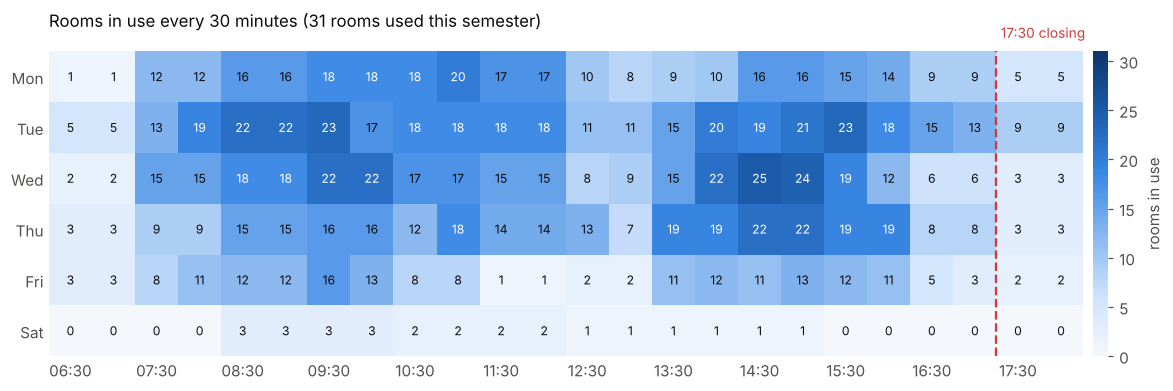

busiest moment: 25 rooms (Wed 14:30) | at that moment 6 of today's rooms are still free
weekday slots (06:30-17:30) with more than half the rooms free: 66 of 110


In [12]:
grid = oc.concurrency(reg, until=oc.CLOSE + 60)

fig, ax = plt.subplots(figsize=(12.5, 3.6))
im = ax.imshow(grid.values, cmap=SEQ, aspect="auto", vmin=0, vmax=NOW)
ax.set_xticks(range(0, grid.shape[1], 2), grid.columns[::2])
ax.set_yticks(range(len(grid.index)), grid.index)
for (i, j), v in pd.DataFrame(grid.values).stack().items():
    ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > NOW * 0.55 else INK)
ax.axvline(list(grid.columns).index("17:30") - .5, color=RED, lw=1.5, ls="--")
ax.text(list(grid.columns).index("17:30") - .4, -.7, "17:30 closing", color=RED, fontsize=9, va="bottom")
ax.set_title(f"Rooms in use every 30 minutes ({NOW} rooms used this semester)", loc="left", fontsize=11, pad=16)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=.02, pad=.01); cb.outline.set_visible(False); cb.set_label("rooms in use")
fig.savefig(IMG / "heatmap.png")
plt.show()

wk = grid.loc[oc.WEEKDAYS]
peak_day, peak_time = wk.stack().idxmax()
PEAK = wk.max().max()
print(f"busiest moment: {PEAK} rooms ({peak_day} {peak_time}) | at that moment {NOW - PEAK} of today's rooms are still free")
print(f"weekday slots (06:30-17:30) with more than half the rooms free: "
      f"{(wk.iloc[:, :22] < NOW / 2).sum().sum()} of {wk.iloc[:, :22].size}")

Two busy blocks show up every weekday, **late morning and mid afternoon**. Even at the busiest moment of the week only
**25 rooms** are in use. Early mornings, lunch time, Friday afternoon and Saturday leave most rooms empty.

**So the building does not lack rooms. The rooms are spread thin.** Every class takes whatever room is free,
so 31 rooms each get a little use instead of fewer rooms being used well.

# Part 2. Scenario: rooms per faculty

## 5. The rule

Each faculty gets its own **home rooms**. Class times stay **exactly as they are**: nothing is moved.

- A class goes into one of its faculty's home rooms.
- Only when all of them are busy does it use a **shared reserve room**.
- **LAC is not counted**: its classes are scheduled in the third week of the semester, into whatever rooms are free.
  The last step checks that they still fit.

Home rooms per faculty (set by ICAO), using the planned room codes after the renovation. Each faculty's rooms sit next to
each other on one floor. KU3.03.01 is the multimedia room, which works on bookings, so it is not part of this plan.

In [13]:
fac_sizes = (reg[reg.program.isin(oc.FACULTY)].assign(faculty=lambda d: d.program.map(oc.FACULTY))
             .groupby("faculty").agg(programs=("program", lambda p: ", ".join(sorted(set(x.replace("S1 ", "").split(" (")[0] for x in p)))),
                                     class_groups=("class_group", "nunique"), classes_per_week=("session_id", "count")))
fac_sizes["home_rooms"] = pd.Series(oc.ALLOCATION)
fac_sizes["rooms"] = pd.Series({f: ", ".join(r.replace("KU3.", "") for r in oc.ROOM_PLAN[f]) for f in oc.ALLOCATION})
fac_sizes = fac_sizes.loc[list(oc.ALLOCATION)]
reserve_n = oc.TOTAL_AFTER - sum(oc.ALLOCATION.values())
print(f"home rooms: {sum(oc.ALLOCATION.values())} | reserve rooms: {reserve_n} "
      f"({', '.join(r.replace('KU3.', '') for r in oc.ROOM_PLAN['Reserve'])}) | total: {oc.TOTAL_AFTER}")
fac_sizes

home rooms: 25 | reserve rooms: 7 (03.19, 03.20, 03.21, 02.10, 02.11, 02.18, 02.19) | total: 32


,programs,class_groups,classes_per_week,home_rooms,rooms
faculty,,,,,
FEB,"Akuntansi, International ICT Business",13,74,6,"03.02, 03.03, 03.04, 03.05, 03.06, 03.07"
FKS,"Administrasi Bisnis, Ilmu Komunikasi",11,52,5,"03.08, 03.09, 03.10, 03.11, 03.12"
FRI,"Sistem Informasi, Teknik Industri",9,43,4,"03.13, 03.14, 03.15, 03.16"
FTE,"Teknik Elektro, Teknik Telekomunikasi",8,32,4,"02.06, 02.07, 02.08, 02.09"
FIF,"Informatika, Teknologi Informasi",7,22,4,"02.14, 02.15, 02.16, 02.17"
FIK,DKV International,6,30,2,"03.17, 03.18"


FRI, FTE and FIF still have international classes in **other buildings**, so this timetable shows only part of their demand.
Their home rooms are sized for the full faculty, which is why they will look less used below.

## 6. Do the classes fit?

The classes of each faculty are placed into its home rooms day by day, in order of end time, each one in the room that
became free most recently. This keeps as many classes as possible in the home rooms, so the reserve is used as little as possible.

In [14]:
plan, plan_rooms, not_placed = oc.faculty_allocation(schedule)
reserve_classes = plan[plan.uses_reserve]
RES_PEAK = oc.concurrency(reserve_classes).loc[oc.DAYS].max().max() if len(reserve_classes) else 0

by_fac = (plan.groupby("faculty").agg(classes=("session_id", "count"), in_reserve=("uses_reserve", "sum"))
          .join(plan_rooms[plan_rooms.group != "Reserve"].groupby("group").agg(home_rooms=("room", "count"),
                avg_use=("utilization", "mean"), free_hours=("free_hours", "sum")))
          .loc[list(oc.ALLOCATION)])
by_fac["in_home_rooms"] = by_fac.classes - by_fac.in_reserve
by_fac = by_fac[["home_rooms", "classes", "in_home_rooms", "in_reserve", "avg_use", "free_hours"]]

print(f"classes placed: {len(plan) - len(not_placed)} of {len(plan)} | moved in time: 0 | using a reserve room: {len(reserve_classes)}")
print(f"reserve rooms busy at the same time, at most: {RES_PEAK} of {reserve_n} -> at least {reserve_n - RES_PEAK} reserve rooms always free")
by_fac.style.format({"avg_use": "{:.0%}", "free_hours": "{:.0f}"})

classes placed: 253 of 253 | moved in time: 0 | using a reserve room: 8
reserve rooms busy at the same time, at most: 2 of 7 -> at least 5 reserve rooms always free


,home_rooms,classes,in_home_rooms,in_reserve,avg_use,free_hours
faculty,,,,,,
FEB,6,74,70,4,59%,135
FKS,5,52,51,1,50%,138
FRI,4,43,43,0,46%,118
FTE,4,32,32,0,36%,141
FIF,4,22,22,0,21%,173
FIK,2,30,27,3,65%,39


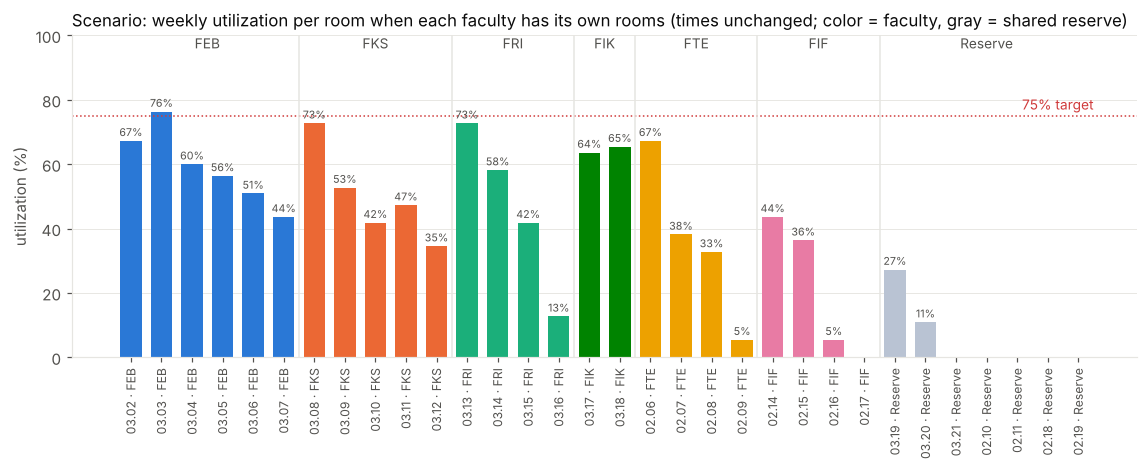

In [15]:
pr = plan_rooms.copy()
palette = {"FEB": "#2a78d6", "FKS": "#eb6834", "FRI": "#1baf7a", "FTE": "#eda100", "FIF": "#e87ba4", "FIK": "#008300", "Reserve": GRAY_BAR}


fig, ax = plt.subplots(figsize=(12.5, 3.8))
ax.bar(pr.label, pr.utilization * 100, color=[palette[g] for g in pr.group], width=.7)
for i, u in enumerate(pr.utilization):
    if u > 0:
        ax.text(i, u * 100 + 1.5, f"{u:.0%}", ha="center", fontsize=7, color=INK_2)
ax.axhline(75, color=RED, lw=1, ls=":"); ax.text(len(pr) - .5, 77, "75% target", ha="right", color=RED, fontsize=9)
for g in palette:
    sub = pr.index[pr.group == g]
    ax.text((sub.min() + sub.max()) / 2, 96, g, ha="center", fontsize=9, color=INK_2)
    if sub.min() > 0:
        ax.axvline(sub.min() - .5, color=GRID, lw=1)
ax.set_ylabel("utilization (%)"); ax.set_ylim(0, 100)
ax.set_title("Scenario: weekly utilization per room when each faculty has its own rooms (times unchanged; color = faculty, gray = shared reserve)", loc="left", fontsize=11)
ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
plt.xticks(rotation=90, fontsize=8)
fig.savefig(IMG / "faculty_rooms.png")
plt.show()

All classes fit without moving a single class time, and the reserve is barely touched.
The first home rooms of each faculty are well used; the last ones carry the faculty's peaks.
FRI, FTE and FIF have the most free hours, which is room for their classes that are still in other buildings.

## 7. Does LAC still fit in week 3?

In [16]:
lac = reg[reg.program == "LAC"]
together = pd.concat([plan, lac])
TOTAL_PEAK = oc.concurrency(together).loc[oc.DAYS].max().max()
lac_peak = oc.concurrency(lac).loc[oc.DAYS].max().max()
print(f"LAC classes per week: {len(lac)} | LAC classes at the same time, at most: {lac_peak}")
print(f"all classes together, at most: {TOTAL_PEAK} of {oc.TOTAL_AFTER} rooms -> at least {oc.TOTAL_AFTER - TOTAL_PEAK} rooms free at every moment")

LAC classes per week: 36 | LAC classes at the same time, at most: 8
all classes together, at most: 25 of 32 rooms -> at least 7 rooms free at every moment


## 8. Is 32 classrooms enough?

Yes. With every class, LAC included, at most **25 rooms** are in use at the same moment, so 32 rooms leave **7 free**
even at the busiest moment. Going from 34 or 36 rooms down to 32 is not a problem, and with international student numbers
staying roughly level, it should stay that way for years.

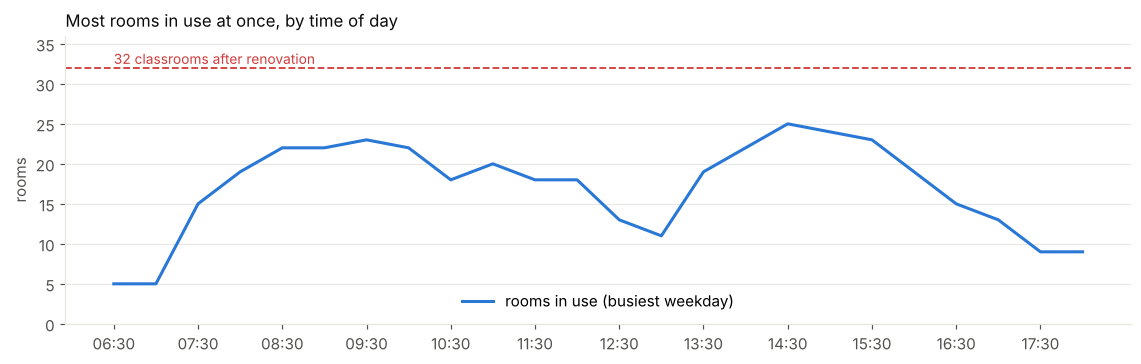

In [17]:
peak_by_slot = oc.concurrency(reg, until=oc.CLOSE + 60).loc[oc.WEEKDAYS].max(axis=0)
fig, ax = plt.subplots(figsize=(12.5, 3.4))
ax.plot(range(len(peak_by_slot)), peak_by_slot.values, color=BLUE, lw=2, label="rooms in use (busiest weekday)")
ax.axhline(oc.TOTAL_AFTER, color=RED, lw=1.2, ls="--")
ax.text(0, oc.TOTAL_AFTER + .5, f"{oc.TOTAL_AFTER} classrooms after renovation", color=RED, fontsize=9)
ax.set_xticks(range(0, len(peak_by_slot), 2), peak_by_slot.index[::2])
ax.set_ylim(0, 36); ax.set_ylabel("rooms")
ax.set_title("Most rooms in use at once, by time of day", loc="left", fontsize=11)
ax.grid(axis="y", color=GRID, lw=.6); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower center")
fig.savefig(IMG / "peak_vs_32.png")
plt.show()

# Appendix

## A. Overtime classes

Classes ending after 17:30 mean overtime for staff. For each one, the search lists **earlier slots on the same day**
(up to 2 hours earlier, ending by 17:30) where the class group, the lecturer and a room are free in this timetable.

**Limit:** this timetable only covers these rooms. Lecturers may teach in other buildings or have meetings, so these are
**candidate slots to confirm with lecturers and study programs**, not changes to make.

In [18]:
ot = reg[(reg.end_min > oc.CLOSE) & reg.day.isin(oc.WEEKDAYS)]
options = oc.overtime_options(schedule, rooms, max_shift_hours=2)
one_hour = options[options.smallest_shift_h == 1]
print(f"weekday classes ending after 17:30: {len(ot)} | with an earlier candidate slot: {(options.alternatives > 0).sum()} | "
      f"one hour earlier possible: {len(one_hour)}")
options[["session_id", "course_name", "class_group", "day", "current_time", "alternatives", "options"]]

weekday classes ending after 17:30: 22 | with an earlier candidate slot: 19 | one hour earlier possible: 19


,session_id,course_name,class_group,day,current_time,alternatives,options
0,S043,TEKNOLOGI BLOCKCHAIN DAN EKONOMI TOKEN,BS1MB-47-REG-01-INT,Mon,14:30-18:30,3,12:30-16:30 (11 rooms); 13:00-17:00 (13 rooms); 13:30-17:30 (15 rooms)
1,S044,BISNIS TEKNOLOGI INFORMASI DAN KOMUNIKASI,BS1MB-50-REG-02-INT,Mon,14:30-18:30,0,none
2,S047,STATISTIKA BISNIS,BS1MB-50-REG-01-INT,Mon,14:30-18:30,3,12:30-16:30 (11 rooms); 13:00-17:00 (13 rooms); 13:30-17:30 (15 rooms)
3,S049,VCD STUDIO 2 - INFORMATION DESIGN,BS1DK-49-INT-01,Mon,14:30-18:30,3,12:30-16:30 (10 rooms); 13:00-17:00 (12 rooms); 13:30-17:30 (14 rooms)
4,S051,SISTEM IOT,BS1TE-48-REG-01-INT,Mon,15:30-18:30,3,13:30-16:30 (15 rooms); 14:00-17:00 (15 rooms); 14:30-17:30 (15 rooms)
5,S115,METODOLOGI PENELITIAN,BS1MB-47-REG-01-INT,Tue,14:30-18:30,3,12:30-16:30 (3 rooms); 13:00-17:00 (3 rooms); 13:30-17:30 (4 rooms)
6,S120,CAPSTONE DESIGN AND PROJECT,BS1SI-47-REG-01-INT,Tue,14:30-18:30,3,12:30-16:30 (4 rooms); 13:00-17:00 (4 rooms); 13:30-17:30 (5 rooms)
7,S123,PERPAJAKAN,AB-49-INT,Tue,15:30-18:30,3,13:30-16:30 (4 rooms); 14:00-17:00 (4 rooms); 14:30-17:30 (6 rooms)
8,S124,LABORATORIUM AKUNTANSI,BS1AK-50-REG-INT,Tue,15:30-18:30,3,13:30-16:30 (4 rooms); 14:00-17:00 (4 rooms); 14:30-17:30 (6 rooms)
9,S125,PERILAKU ORGANISASI,BS1MB-49-REG-02-INT,Tue,15:30-18:30,0,none


## B. Timetable entries to check

The three entries from section 1, to pass to the scheduling team.

In [19]:
issues

,issue,day,sessions,detail
0,class group in two places,Fri,"S248, S252",BS1MB-47-REG-02-INT: BAHASA INDONESIA 06:30-08:30 (KU3.03.19) and E-COMMERCE 07:30-11:30 (KU3.09.05)
1,class during Friday prayer,Fri,S265,STRATEGI DAN KEBIJAKAN BISNIS (AB-49-INT) 09:30-13:30
2,likely input error (late night),Sat,S290,"PRAKTIKUM SINYAL DISKRET, OTOMATISASI, & IOT (BS1TE-48-REG-01-INT) 20:30-23:30"


## Findings and recommendations

**How the rooms are used today**
- 290 classes a week use **31 rooms**. Average use is **42%**; **no room reaches 75%** and **7 rooms are under 30%**.
- Use is uneven: from 73% (KU3.09.21) down to 13% (KU3.03.11). **13 rooms have at least one weekday with no class at all.**
- Even at the busiest moment (Wednesday 14:30) only **25 rooms** are in use.

**Scenario: rooms per faculty, times unchanged**
- With FEB 6 (03.02 to 03.07), FKS 5 (03.08 to 03.12), FRI 4 (03.13 to 03.16), FIK 2 (03.17 to 03.18), FTE 4 (02.06 to 02.09) and FIF 4 (02.14 to 02.17), plus **7 shared reserve rooms** (03.19 to 03.21, 02.10, 02.11, 02.18, 02.19), **every class fits without moving any class time**.
- Only 8 classes a week need a reserve room, and **at least 5 reserve rooms are always free**.
- LAC, scheduled in week 3, still fits: all classes together use at most 25 of 32 rooms.
- FRI, FTE and FIF home rooms have the most free hours, ready for their classes that are still in other buildings.

**Recommendations**
1. **Go ahead with 32 classrooms.** The reduction from 34 or 36 is not a problem.
2. **Give each faculty fixed home rooms** (FEB 6, FKS 5, FRI 4, FTE 4, FIF 4, FIK 2) and keep **7 rooms as a shared reserve**
   for overflow, LAC, replacement classes and bookings.
3. **Bring FRI, FTE and FIF classes from other buildings** into their home rooms, which have room for them.
4. **Review overtime classes and the flagged entries** with the study programs (appendix).
5. **Track use every semester.** Once the faculty rooms are in place, the next step toward 75% per room is to spread class start times more evenly.